# Growing-Season Water Stress Indicator for Slovakia
**Scenario:** RCP 4.5 · **Period:** 2011–2040 vs 1971–2000 · **Season:** April–September

## Source data and model chain
C3S *Hydrology-related climate impact indicators from 1970 to 2100 derived from bias adjusted European climate projections*, produced by SMHI for the Copernicus Climate Change Service.
- 8 EURO-CORDEX climate simulations (combinations of 3 global and 4 regional climate models), each driving 2 gridded hydrological models (E-HYPEgrid and VIC-WUR): 16 ensemble members on a 5 km grid.
- Climate-model output was bias-adjusted to EFAS-Meteo reference data (1990–2018) before driving the hydrological models.

Contains modified Copernicus Climate Change Service information (2026); DOI 10.24381/cds.73237ad6; CC-BY 4.0. Neither the European Commission nor ECMWF is responsible for any use that may be made of the Copernicus information or data it contains.

Administrative boundaries: © EuroGeographics for the administrative boundaries (Eurostat GISCO, Countries 2020, 1:1 million).

# Summary and design decisions
The notebook demonstrates a 5-level categorical indicator (1 = very low to 5 = very high) of the change in growing-season water stress, classified from the ensemble median of two metrics:
- **PET/P change (%):** potential evapotranspiration divided by precipitation, the inverse of UNEP's aridity index (P/PET). Higher = drier.
- **Runoff loss (%):** modelled runoff, a proxy for water availability. The source gives relative change; the sign is flipped so that positive = less runoff (drier).

Every class is reported with its robustness (model agreement on the direction of change) and class agreement (share of models in the same class).

**#1. Imports and Parameters**

In [1]:
import calendar
import zipfile
import json
from pathlib import Path
import os 
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import shapely
import itertools                                                                
from tqdm import tqdm          
from pyproj import Transformer
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap, TwoSlopeNorm

# ---------------------PATHS---------------------
DATA_DIR      = Path("../data")
HYDRO_DIR     = DATA_DIR / "hydrology"
OUT_DIR       = DATA_DIR / "processed"
BOUNDARY_FILE = DATA_DIR / "boundary" / "slovakia_epsg3035.gpkg"   
OUT_DIR.mkdir(parents=True, exist_ok=True)


#---------------------PARAMETERS---------------------
ANALYSIS_CRS      = "EPSG:3035"                                    # ETRS89-LAEA equal-area projection.
CELL_SIZE_M       = 5000                                           # 5km grid for gridded data  
GRID_TOL_M        = 50                                             # Grid tolerance (deviation from perfect grid)

# Months chosen
GROWING_MONTHS    = [4, 5, 6, 7, 8, 9]                             # April to September

# Runoff is mean percent change and sign-flipped, becomes runoff loss (higher number = higher loss) runoff_loss_pct = -(mean % change)
# Aridity is mean percent change of PET/P ratio, per data.
RUNOFF_LOSS_EDGES = [0, 10, 20, 30]                                # class boundaries (lower) for modelled runoff % delta.
ARIDITY_EDGES     = [0, 10, 20, 40]                                # class boundaries (lower) for PET/P % delta.
CLASS_NAMES = {1: "very low", 2: "low", 3: "moderate", 4: "high", 5: "very high"}

# A bounding box for clipping to Slovakia
LAT_MIN, LAT_MAX = 47.7, 49.6
LON_MIN, LON_MAX = 16.8, 22.6


**#2. Package Version Printout**

In [2]:
#Prints every library's version number if installed to record those used for analysis, or alert if they are not installed. Any other error types will still come through.

import importlib.metadata as md

for pkg in ["cdsapi", "tqdm", "netCDF4", "xarray", "geopandas", "shapely", "pyproj", "numpy", "scipy", "pandas", "matplotlib"]:
    try:
        print(f"{pkg:12s}{md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"{pkg:12s}not installed")

cdsapi      0.7.7
tqdm        4.67.3
netCDF4     1.7.4
xarray      2025.6.1
geopandas   1.1.2
shapely     2.1.2
pyproj      3.7.2
numpy       1.26.4
scipy       1.15.2
pandas      2.1.4
matplotlib  3.10.8


**#3. Data retrieval**

Downloading an ensemble of climate model runs for managing model uncertainty.
This notebook is all 2011-2040 for now.

In [3]:
# ENSEMBLE DOWNLOAD SETTINGS
                                            
CDS_DATASET  = "sis-hydrology-variables-derived-projections"
EXPERIMENT   = "rcp_4_5"                                                        # Scenario for this workbook
PERIOD       = "2011_2040"
GCMS         = ["ec_earth", "hadgem2_es", "mpi_esm_lr"]                         # EC-EARTH, Met Office HadGEM2-ES, MPI-ESM-LR
RCMS         = ["cclm4_8_17", "racmo22e", "csc_remo2009", "rca4"]               # CCLM4-8-17, KNMI RACMO22E, GERICS REMO2009, SMHI RCA4
MEMBERS      = ["r1i1p1", "r2i1p1", "r12i1p1"]                                  # 3 different members for demo purposes
HYDRO_MODELS = ["e_hypegrid", "vic_wur"]                                        # Gridded models only here. Catchment & polygons work to be in separate notebook. 
ENS_DIR      = HYDRO_DIR / f"ensemble_{PERIOD.replace('_', '-')}_grid"
REPO_RC      = Path("../.cdsapirc").resolve()

In [4]:
def have_cds_credentials():
    """True if cdsapi can find a key in environment; falls back to a gitignore'd repo-local .cdsapirc. Mine is .gitignore'd repo-local."""
    env_ok = "CDSAPI_URL" in os.environ and "CDSAPI_KEY" in os.environ
    rc = Path(os.environ.get("CDSAPI_RC", "~/.cdsapirc")).expanduser()
    if env_ok or rc.exists():
        return True
    if REPO_RC.exists():
        os.environ["CDSAPI_RC"] = str(REPO_RC)
        return True
    return False


def ens_request(hm, gcm, rcm, member):
    """CDS request for one hydrological model x GCM x RCM x member combination."""
    return {
        "product_type": "climate_impact_indicators",
        "variable": ["mean_runoff", "aridity_potential"],
        "variable_type": "relative_change_from_reference_period",
        "time_aggregation": "monthly_mean",
        "experiment": [EXPERIMENT],
        "hydrological_model": [hm],
        "rcm": rcm,
        "gcm": gcm,
        "ensemble_member": [member],
        "period": [PERIOD],
    }


def fetch_member(hm, gcm, rcm, member):
    """Download (if not cached) and extract one member. Raises if the CDS rejects the combination."""
    zip_path = ENS_DIR / f"{EXPERIMENT}_{PERIOD}_{hm}_{gcm}_{rcm}_{member}.zip"
    if not zip_path.exists():
        import cdsapi
        if not have_cds_credentials():
            raise RuntimeError(
                "No CDS credentials found. Create ~/.cdsapirc or set CDSAPI_URL and CDSAPI_KEY "
                "(see README), and accept the dataset licence on the CDS website."
            )
        cdsapi.Client().retrieve(CDS_DATASET, ens_request(hm, gcm, rcm, member)).download(str(zip_path))
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(ENS_DIR)


# ---------------------RUN---------------------
ENS_DIR.mkdir(parents=True, exist_ok=True)
combos = list(itertools.product(HYDRO_MODELS, GCMS, RCMS, MEMBERS))             # 2 models x 3 GCMs x 4 RCMs x 3 members = 72 candidates
ok, skipped = [], []

for combo in tqdm(combos, desc="ensemble members"):
    try:
        fetch_member(*combo)
        ok.append(combo)
    except RuntimeError as e:
        if "credentials" in str(e):
            raise
        skipped.append((combo, str(e)))
    except Exception as e:
        skipped.append((combo, str(e)))


print(f"downloaded or cached: {len(ok)} | skipped: {len(skipped)} of {len(combos)}")
for hm in HYDRO_MODELS:
    print(f"  {hm:11s}{sum(c[0] == hm for c in ok)} members")
print("\nmembers:")
for c in ok:
    print("  ", " | ".join(c))
if skipped:
    print(f"\nexample skip reason: {skipped[0][0]} -> {skipped[0][1][:150]}")

print(f"\nNetCDF files in {ENS_DIR.name}/: {len(list(ENS_DIR.glob('*.nc')))}")

ensemble members:   0%|          | 0/72 [00:00<?, ?it/s]2026-10-20 14:48:35,558 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
ensemble members:   1%|▏         | 1/72 [00:02<03:00,  2.55s/it]2026-10-20 14:48:37,928 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the c

downloaded or cached: 16 | skipped: 56 of 72
  e_hypegrid 8 members
  vic_wur    8 members

members:
   e_hypegrid | ec_earth | cclm4_8_17 | r12i1p1
   e_hypegrid | ec_earth | racmo22e | r12i1p1
   e_hypegrid | ec_earth | rca4 | r12i1p1
   e_hypegrid | hadgem2_es | racmo22e | r1i1p1
   e_hypegrid | hadgem2_es | rca4 | r1i1p1
   e_hypegrid | mpi_esm_lr | csc_remo2009 | r1i1p1
   e_hypegrid | mpi_esm_lr | csc_remo2009 | r2i1p1
   e_hypegrid | mpi_esm_lr | rca4 | r1i1p1
   vic_wur | ec_earth | cclm4_8_17 | r12i1p1
   vic_wur | ec_earth | racmo22e | r12i1p1
   vic_wur | ec_earth | rca4 | r12i1p1
   vic_wur | hadgem2_es | racmo22e | r1i1p1
   vic_wur | hadgem2_es | rca4 | r1i1p1
   vic_wur | mpi_esm_lr | csc_remo2009 | r1i1p1
   vic_wur | mpi_esm_lr | csc_remo2009 | r2i1p1
   vic_wur | mpi_esm_lr | rca4 | r1i1p1

example skip reason: ('e_hypegrid', 'ec_earth', 'cclm4_8_17', 'r1i1p1') -> 400 Client Error: Bad Request for url: https://cds.climate.copernicus.eu/api/retrieve/v1/processes/sis-hy

**#4 Load and examine the data in the ensemble folder**
This will create a table of each model/GCM/RCM/member for reference

In [5]:
def period_tag(period):                                                                 # For desired period, changes e.g. "2011_2040" -> "_2011-2040_" to match file names
    return "_" + period.replace("_", "-") + "_"

KEY_FIELDS = ["hydro_model", "gcm", "rcp", "member", "rcm"]                             # Filename parts 3-7, e.g. E-HYPEgrid-EUR-11 | ICHEC-EC-EARTH | rcp45 | r12i1p1 | CLMcom-CCLM4-8-17-v1

def parse_member(path):
    """Split a CDS file name into its model fields; flag names that don't follow the expected layout."""
    parts = path.name.split("_")
    fields = dict(zip(KEY_FIELDS, parts[3:8]))
    fields["key"] = "_".join(parts[3:8])
    fields["layout_ok"] = len(parts) > 8 and parts[8] == PERIOD.replace("_", "-")       # part 8 should be the period
    return fields


member_rows = []                                                                        # Loop: one row per runoff file
for run_f in sorted(ENS_DIR.glob(f"run_ymonmean_rel_*{period_tag(PERIOD)}*.nc")):
    arid_f = run_f.with_name(run_f.name.replace("run_ymonmean", "aridpot_ymonmean", 1)) # matching aridity file
    member_rows.append({**parse_member(run_f),
                 "run_path": run_f,
                 "arid_path": arid_f if arid_f.exists() else None})

members = pd.DataFrame(member_rows)                                                     # The members table
assert len(members), f"no runoff files for {PERIOD} in {ENS_DIR}"

bad = members[~members["layout_ok"] | members["arid_path"].isna()]                      # Unexpected names or missing aridity
if len(bad):
    print("WARNING: excluded (unexpected file name or no aridity file):")
    for k in bad["key"]:
        print("  ", k)
members = members[members["layout_ok"] & members["arid_path"].notna()].reset_index(drop=True)

print(f"{len(members)} usable members for {PERIOD.replace('_', '-')}")
display(members[KEY_FIELDS])                                                            # Review the ensemble composition

# A single reference member supplies the lat/lon grid for #5–#9
REF_KEY = "E-HYPEgrid-EUR-11_ICHEC-EC-EARTH_rcp45_r12i1p1_CLMcom-CCLM4-8-17-v1"
ref = members[members["key"] == REF_KEY]
if len(ref) == 0:                                                                       # Fallback to any E-HYPEgrid member
    ref = members[members["hydro_model"].str.startswith("E-HYPEgrid")]
ref = ref.iloc[0]

ds_run  = xr.open_dataset(ref["run_path"])
print("reference grid member:", ref["key"])
ds_run                                                                                  # Displays the reference dataset xarray; lazy loading so this needs to be called before ds_run[lat] and ds_run[lon] below

16 usable members for 2011-2040


,hydro_model,gcm,rcp,member,rcm
0,E-HYPEgrid-EUR-11,ICHEC-EC-EARTH,rcp45,r12i1p1,CLMcom-CCLM4-8-17-v1
1,E-HYPEgrid-EUR-11,ICHEC-EC-EARTH,rcp45,r12i1p1,KNMI-RACMO22E-v1
2,E-HYPEgrid-EUR-11,ICHEC-EC-EARTH,rcp45,r12i1p1,SMHI-RCA4-v1
3,E-HYPEgrid-EUR-11,MOHC-HadGEM2-ES,rcp45,r1i1p1,KNMI-RACMO22E-v2
4,E-HYPEgrid-EUR-11,MOHC-HadGEM2-ES,rcp45,r1i1p1,SMHI-RCA4-v1
5,E-HYPEgrid-EUR-11,MPI-M-MPI-ESM-LR,rcp45,r1i1p1,MPI-CSC-REMO2009-v1
6,E-HYPEgrid-EUR-11,MPI-M-MPI-ESM-LR,rcp45,r1i1p1,SMHI-RCA4-v1a
7,E-HYPEgrid-EUR-11,MPI-M-MPI-ESM-LR,rcp45,r2i1p1,MPI-CSC-REMO2009-v1
8,VIC-WUR-EUR-11,ICHEC-EC-EARTH,rcp45,r12i1p1,CLMcom-CCLM4-8-17-v1
9,VIC-WUR-EUR-11,ICHEC-EC-EARTH,rcp45,r12i1p1,KNMI-RACMO22E-v1


reference grid member: E-HYPEgrid-EUR-11_ICHEC-EC-EARTH_rcp45_r12i1p1_CLMcom-CCLM4-8-17-v1


<xarray.Dataset> Size: 53MB
Dimensions:       (y: 950, x: 1000, time: 12)
Coordinates:
    lon           (y, x) float32 4MB ...
  * time          (time) datetime64[ns] 96B 2040-01-01 2040-02-01 ... 2040-12-01
Dimensions without coordinates: y, x
Data variables:
    lat           (y, x) float32 4MB ...
    run_ymonmean  (time, y, x) float32 46MB ...
Attributes: (12/28)
    CDI:                      Climate Data Interface version 1.9.8 (https://m...
    NCO:                      "4.6.3"
    title:                    Mean monthly runoff
    summary:                  Calculated as the monthly mean values of daily ...
    keywords:                 runoff, flux
    reference_period:         1971-2000
    ...                       ...
    acknowledgements:         This work was performed within Copernicus Clima...
    data_quality:             C3S_424_SMHI uses state of the art, quality con...
    references:               Hundecha et al., 2016 (doi.org/10.1016/j.ejrh.2...
    variable_name:            run_ymonmean
    history:                  CDO commands (last cdo command first and separa...
    contact:                  copernicus-support@ecmwf.int

**#5. Verifying units, grids, and month axes match across all ensemble members**

In [6]:
ref_lat = ds_run["lat"].values                                                          # Reference dataset grid
ref_lon = ds_run["lon"].values                                                          # Reference dataset grid

def month_numbers(ds):
    """Calendar month (1-12) of each time step."""
    try:
        return np.asarray(ds["time"].dt.month.values)
    except (TypeError, AttributeError):
        tqdm.write("WARNING: time is not decoded as dates; ASSUMING the 12 steps are Jan..Dec in order.")
        return np.arange(1, ds.sizes["time"] + 1)

# Verifying months numbering is the same 

months_ref = month_numbers(ds_run)                                                      # Months numbering of the reference dataset
print("time stamps:", [str(t)[:10] for t in ds_run["time"].values])
print("months     :", months_ref)
assert sorted(months_ref) == list(range(1, 13)), "expected exactly one step per calendar month"

checks = []
for row in tqdm(members.itertuples(), total=len(members), desc="checking members"):
    for var, path in [("run_ymonmean", row.run_path), ("aridpot_ymonmean", row.arid_path)]:
        with xr.open_dataset(path) as ds:                                               # 'With' closes each file after checking
            has_grid = "lat" in ds.variables and "lon" in ds.variables
            same_grid = (has_grid
                         and ds["lat"].shape == ref_lat.shape                           # Shape first: allclose fails on mismatched shapes
                         and np.allclose(ds["lat"].values, ref_lat, equal_nan=True)     # Checks if latitudes within floating point tolerance
                         and np.allclose(ds["lon"].values, ref_lon, equal_nan=True))    # Checks if longitudes within floating point tolerance
            m = month_numbers(ds)
            checks.append({
                "key": row.key,
                "variable": var,
                "same_grid": bool(same_grid),
                "same_months": len(m) == 12 and bool((m == months_ref).all()),
                "units": ds[var].attrs.get("units") if var in ds else "VARIABLE MISSING",
                "long_name": ds[var].attrs.get("long_name") if var in ds else None,
            })

checks = pd.DataFrame(checks)

print("\nunits by variable:")
display(checks.groupby(["variable", "units"]).size().rename("files").to_frame())

problems = checks[~checks["same_grid"] | ~checks["same_months"] | (checks["units"] != "%")]
if len(problems):
    display(problems)
assert problems.empty, f"{len(problems)} files differ from the reference grid, month axis or units; see table above"
print(f"OK: all {len(checks)} files share the reference grid, month axis and % units.")

time stamps: ['2040-01-01', '2040-02-01', '2040-03-01', '2040-04-01', '2040-05-01', '2040-06-01', '2040-07-01', '2040-08-01', '2040-09-01', '2040-10-01', '2040-11-01', '2040-12-01']
months     : [ 1  2  3  4  5  6  7  8  9 10 11 12]


checking members: 100%|██████████| 16/16 [00:00<00:00, 21.47it/s]


units by variable:


,,files
variable,units,
aridpot_ymonmean,%,16
run_ymonmean,%,16


OK: all 32 files share the reference grid, month axis and % units.


**#6. Convert reference grid to EPSG:3035 and verify everything worked**

In [7]:
# conversion tool for EPSG:4326 to EPSG:3035. "always_xy=True" forces (x,y) which makes (lon, lat) match (easting, northing) from EPSG:3035
to_laea = Transformer.from_crs("EPSG:4326", ANALYSIS_CRS, always_xy=True)

# extract the position grids from the netCDF and limit further rounding by converting to float64  
lon2d = ds_run["lon"].values.astype("float64")      
lat2d = ds_run["lat"].values.astype("float64")      

# apply the conversion tool from above to lon and lat, outputting X and Y in meters east, north.
X, Y = to_laea.transform(lon2d, lat2d)              
X, Y = np.asarray(X), np.asarray(Y)
assert np.isfinite(X).all() and np.isfinite(Y).all(), "some cell centres could not be projected"

# dx is a step horizontally, dy is a step vertically.
dx = np.diff(X, axis=1)
dy = np.diff(Y, axis=0)
drift_x = np.ptp(X, axis=0).max()   # X should be constant (or close enough)
drift_y = np.ptp(Y, axis=1).max()   # Y should be constant (or close enough)

# prints min and max step sizes between grid cells to ensure within tolerance.
print(f"x step along rows   : {dx.min():10.2f} .. {dx.max():10.2f} m   (expect +/-{CELL_SIZE_M})")
print(f"y step down columns : {dy.min():10.2f} .. {dy.max():10.2f} m   (expect +/-{CELL_SIZE_M})")
print(f"max X drift down a column: {drift_x:8.2f} m   | max Y drift along a row: {drift_y:8.2f} m")

# if TRUE, the drift/error is within 50m (+/-1%) tolerance.
GRID_IS_REGULAR = bool(
    np.abs(np.abs(dx) - CELL_SIZE_M).max() < GRID_TOL_M
    and np.abs(np.abs(dy) - CELL_SIZE_M).max() < GRID_TOL_M
    and drift_x < GRID_TOL_M
    and drift_y < GRID_TOL_M
)
print("\nregular 5 km EPSG:3035 lattice:", GRID_IS_REGULAR)
if GRID_IS_REGULAR:
    x1d = np.median(X, axis=0)   # one x per column
    y1d = np.median(Y, axis=1)   # one y per row
    print(f"first cell centre (row 0, col 0): x={x1d[0]:.0f} m, y={y1d[0]:.0f} m")
else:
    print("NOT regular: continuing with the 2-D X/Y arrays only.")

x step along rows   :    4999.36 ..    5000.64 m   (expect +/-5000)
y step down columns :    4999.17 ..    5000.84 m   (expect +/-5000)
max X drift down a column:     0.68 m   | max Y drift along a row:     0.84 m

regular 5 km EPSG:3035 lattice: True
first cell centre (row 0, col 0): x=2502500 m, y=752500 m


**#7. Clip a box to the study area around Slovakia**

This is a good practice for managing memory in big geodata operations, but also focuses statistics on Slovakia without including irrelevant values from elsewhere in Europe.

In [8]:
# Apply a boolean mask, with "TRUE" on cells within the lat/lon box defined previously.
box = (lat2d >= LAT_MIN) & (lat2d <= LAT_MAX) & (lon2d >= LON_MIN) & (lon2d <= LON_MAX)

# Checks if any row contains a "True" and returns index of the values (i.e. positions) that are "True".
rows = np.flatnonzero(box.any(axis=1))

# Checks if any column contains a "True" and returns index of the values (i.e. positions) that are "True".
cols = np.flatnonzero(box.any(axis=0))

# Define the window as a slice between the minimum and maximum (+1) values of 'rows' and 'cols'.
win = {"y": slice(rows.min(), rows.max() + 1), "x": slice(cols.min(), cols.max() + 1)}

Xw, Yw = X[win["y"], win["x"]], Y[win["y"], win["x"]]                     # meters in EPSG:3035
lon_w  = lon2d[win["y"], win["x"]]                                        # degrees east
lat_w  = lat2d[win["y"], win["x"]]                                        # degrees north

print("window shape (y, x):", Xw.shape, "->", Xw.size, "cells =", Xw.size * (CELL_SIZE_M / 1000) ** 2, "km2")

window shape (y, x): (53, 90) -> 4770 cells = 119250.0 km2


**#8. Clip precisely to Slovakia's boundary**

Using the GISCO European 1:1 million GeoJSON for boundary, by ISO3 code for Slovakia "SVK."

In [9]:
GISCO_URL = ("https://gisco-services.ec.europa.eu/distribution/v2/countries/geojson/"
             "CNTR_RG_01M_2020_4326.geojson")
GISCO_SOURCE = "Eurostat GISCO countries 1:1M (2020)"

def load_boundary():
    """Slovakia as a single polygon in ANALYSIS_CRS. Cached on disk as GPKG."""
    if BOUNDARY_FILE.exists():
        return gpd.read_file(BOUNDARY_FILE).to_crs(ANALYSIS_CRS)
    countries = gpd.read_file(GISCO_URL)
    if countries.crs is None:
        countries = countries.set_crs("EPSG:4326")
    sk = countries[countries["ISO3_CODE"] == "SVK"].to_crs(ANALYSIS_CRS)
    assert len(sk) > 0, f"Slovakia not found; columns are {list(countries.columns)}"
    result = gpd.GeoDataFrame({"name": ["Slovakia"], "source": [GISCO_SOURCE]},
                              geometry=[sk.geometry.union_all()], crs=ANALYSIS_CRS)
    BOUNDARY_FILE.parent.mkdir(parents=True, exist_ok=True)
    result.to_file(BOUNDARY_FILE, driver="GPKG")
    return result

# Apply the boundary. Union_all() is a habit for safety but only necessary if country would be multiple polygons (e.g. islands)
boundary = load_boundary()
sk_poly = boundary.geometry.union_all()
shapely.prepare(sk_poly)                                                        # in-memory speed-up for point-in-polygon tests below

print(f"vertices: {shapely.get_num_coordinates(sk_poly)} | area: {sk_poly.area / 1e6:,.0f} km2 | "
      f"bounds (km): {[round(b / 1e3, 1) for b in sk_poly.bounds]}")

vertices: 1615 | area: 49,024 km2 | bounds (km): [4826.6, 2766.9, 5234.0, 2992.6]


**#9. Apply a Slovakia-shaped mask for the final trim.**

In [10]:
CELL_KM2 = (CELL_SIZE_M / 1000) ** 2

inside = shapely.contains_xy(sk_poly, Xw.ravel(), Yw.ravel()).reshape(Xw.shape)
n_in = int(inside.sum())
ratio = n_in * CELL_KM2 / (sk_poly.area / 1e6)
print(f"cells with centre inside Slovakia: {n_in} = {n_in * CELL_KM2:,.0f} km2 | polygon: {sk_poly.area / 1e6:,.0f} km2 | difference {100 * (ratio - 1):+.1f} %")
assert 0.9 < ratio < 1.1, "grid and polygon do not line up: check the CRS of both before going on"

# The whole polygon must lie inside the window, otherwise border cells are missing
wx0, wx1, wy0, wy1 = Xw.min(), Xw.max(), Yw.min(), Yw.max()
px0, py0, px1, py1 = sk_poly.bounds                                             # shapely order: minx, miny, maxx, maxy

# This prints the distance in km between the polygon edge and the box around it to ensure no points were missed. Should be positive numbers.
print("margin between polygon and window edge (km): "
      f"W {(px0 - wx0)/1e3:.0f}, E {(wx1 - px1)/1e3:.0f}, S {(py0 - wy0)/1e3:.0f}, N {(wy1 - py1)/1e3:.0f}")

cells with centre inside Slovakia: 1962 = 49,050 km2 | polygon: 49,024 km2 | difference +0.1 %
margin between polygon and window edge (km): W 14, E 23, S 9, N 25


**#10. QAQC Table For Each Ensemble Member**

In [11]:
# List of the index positions of growing season months (begins with 0)
season_idx = np.flatnonzero(np.isin(months_ref, GROWING_MONTHS))
print("growing-season time steps:", season_idx, "-> months",
      [calendar.month_abbr[int(m)] for m in months_ref[season_idx]])


def monthly_table(da, label):
    '''One row per growing season month with spread, missing data counts, and QAQC for extreme values.
    Outputs pandas df.'''
    out = []
    for k in season_idx:
        v = da.isel(time=k).values[inside]
        n_missing = int((~np.isfinite(v)).sum())
        v = v[np.isfinite(v)]
        out.append({
            "variable": label,
            "month": calendar.month_abbr[int(months_ref[k])],
            "n_cells": v.size,
            "n_missing": n_missing,
            "p5": np.percentile(v, 5),
            "median": np.median(v),
            "p95": np.percentile(v, 95),
            "max": v.max(),
            "pct_at_-100": 100 * (v <= -99.9).mean(),
            "pct_above_500": 100 * (v > 500).mean(),
        })
    return pd.DataFrame(out)


qc_parts = []                                                                   # One table per member x variable
for row in tqdm(members.itertuples(), total=len(members), desc="QC members"):   # Loops over each member
    for var, label, path in [("run_ymonmean", "runoff", row.run_path),
                             ("aridpot_ymonmean", "aridity", row.arid_path)]:
        with xr.open_dataset(path) as ds:
            da = ds[var].isel(win).load().astype("float64")
        t = monthly_table(da, label)
        t.insert(0, "rcm", row.rcm)                                             # Identify the member in each row by rcm, gcm, model, etc.
        t.insert(0, "gcm", row.gcm)                                             # Identify the member in each row by rcm, gcm, model, etc.
        t.insert(0, "hydro_model", row.hydro_model)                             # Identify the member in each row by rcm, gcm, model, etc.
        qc_parts.append(t)

qc = pd.concat(qc_parts, ignore_index=True).round(1)
qc["month"] = pd.Categorical(qc["month"],                                       # Months as categorical variables, defined in GROWING_MONTHS from parameters cell
                             categories=[calendar.month_abbr[m] for m in GROWING_MONTHS], ordered=True)

flagged = qc[(qc["n_missing"] > 0) | (qc["pct_at_-100"] > 0) | (qc["pct_above_500"] > 0)]
if len(flagged):
    print(f"WARNING: {len(flagged)} member-months with missing values, -100 % or > +500 %:")
    display(flagged)
else:
    print(f"OK: all {len(qc)} member-months clean (no missing, no -100 %, nothing above +500 %).")

print("\nSpread of member medians across the ensemble (inside Slovakia):")
display(qc.pivot_table(index=["variable", "month"], values="median",
                       aggfunc=["min", "median", "max"], observed=True).round(1))

print("\nMedian of member medians, by hydrological model:")
display(qc.pivot_table(index=["variable", "month"], columns="hydro_model", values="median",
                       aggfunc="median", observed=True).round(1))

growing-season time steps: [3 4 5 6 7 8] -> months ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep']


QC members: 100%|██████████| 16/16 [00:01<00:00, 13.12it/s]

,hydro_model,gcm,rcm,variable,month,n_cells,n_missing,p5,median,p95,max,pct_at_-100,pct_above_500
23,E-HYPEgrid-EUR-11,ICHEC-EC-EARTH,KNMI-RACMO22E-v1,aridity,Sep,1962,0,7.0,34.8,107.9,534.9,0.0,0.1
39,E-HYPEgrid-EUR-11,MOHC-HadGEM2-ES,KNMI-RACMO22E-v2,runoff,Jul,1962,0,-7.6,39.6,161.1,576.8,0.0,0.2
58,E-HYPEgrid-EUR-11,MOHC-HadGEM2-ES,SMHI-RCA4-v1,aridity,Aug,1962,0,-53.9,-17.1,48.1,593.7,0.0,0.2
72,E-HYPEgrid-EUR-11,MPI-M-MPI-ESM-LR,SMHI-RCA4-v1a,runoff,Apr,1962,0,-3.2,10.3,67.9,552.8,0.0,0.1
82,E-HYPEgrid-EUR-11,MPI-M-MPI-ESM-LR,SMHI-RCA4-v1a,aridity,Aug,1962,0,-44.1,-5.5,27.9,744.3,0.0,0.1
83,E-HYPEgrid-EUR-11,MPI-M-MPI-ESM-LR,SMHI-RCA4-v1a,aridity,Sep,1962,0,-3.4,13.9,64.6,524.1,0.0,0.1
90,E-HYPEgrid-EUR-11,MPI-M-MPI-ESM-LR,MPI-CSC-REMO2009-v1,aridity,Apr,1962,0,-3.9,37.8,250.5,604.7,0.0,0.2
96,VIC-WUR-EUR-11,ICHEC-EC-EARTH,CLMcom-CCLM4-8-17-v1,runoff,Apr,1962,0,31.0,104.4,316.4,668.6,0.0,0.5
114,VIC-WUR-EUR-11,ICHEC-EC-EARTH,KNMI-RACMO22E-v1,aridity,Apr,1962,0,-39.6,-4.1,90.0,514.2,0.0,0.1
119,VIC-WUR-EUR-11,ICHEC-EC-EARTH,KNMI-RACMO22E-v1,aridity,Sep,1962,0,7.0,38.5,123.4,955.0,0.0,0.4



Spread of member medians across the ensemble (inside Slovakia):


min median    max
               median median median
variable month                     
aridity  Apr    -48.9   -2.4   37.8
         May    -27.3   -8.8   65.2
         Jun    -42.3   11.8   21.5
         Jul    -65.8   10.9   67.3
         Aug    -68.9  -10.9   59.4
         Sep    -39.3   13.2   54.8
runoff   Apr      0.4   11.0  325.2
         May     -4.0   13.2  154.7
         Jun    -16.7   10.2   90.5
         Jul    -21.0    9.2   65.7
         Aug    -17.7   16.5   67.4
         Sep    -22.2    2.0   55.4


Median of member medians, by hydrological model:


hydro_model     E-HYPEgrid-EUR-11  VIC-WUR-EUR-11
variable month                                   
aridity  Apr                  2.0           -11.9
         May                 -5.2            -9.1
         Jun                 14.4             9.2
         Jul                 12.0            10.0
         Aug                 -9.9           -14.2
         Sep                 16.2             4.7
runoff   Apr                  8.6            25.7
         May                 10.1            17.5
         Jun                  8.5            11.1
         Jul                 12.7             7.2
         Aug                 17.2            11.9
         Sep                 -1.9             8.6

**#11. Creating the Water Stress Indicator**

In [12]:
def score_from_edges(values, edges):
    """Map values to classes 1 (very low water stress) to 5 (very high water stress), using [lower, upper) bins."""
    values = np.asarray(values, dtype="float64")
    edges = np.asarray(edges, dtype="float64")
    score = np.digitize(values, edges) + 1.0
    score[~np.isfinite(values)] = np.nan
    return score

def edges_table(edges, label):
    '''Produces a simple table of the boundaries (edges) of each indicator category, as defined in the parameters cell'''
    lows, highs = [-np.inf] + list(edges), list(edges) + [np.inf]
    rows = []
    for c, (lo, hi) in enumerate(zip(lows, highs), start=1):
        if np.isinf(lo):
            text = f"< {hi:g}"
        elif np.isinf(hi):
            text = f">= {lo:g}"
        else:
            text = f"{lo:g} to < {hi:g}"
        rows.append({"class": c, "name": CLASS_NAMES[c], label: text})
    return pd.DataFrame(rows).set_index("class")

display(edges_table(RUNOFF_LOSS_EDGES, "runoff loss (%)").join(edges_table(ARIDITY_EDGES, "PET/P change (%)")[["PET/P change (%)"]]))

,name,runoff loss (%),PET/P change (%)
class,,,
1,very low,< 0,< 0
2,low,0 to < 10,0 to < 10
3,moderate,10 to < 20,10 to < 20
4,high,20 to < 30,20 to < 40
5,very high,>= 30,>= 40


**#12. Growing Season Mean Values Per Member & Sensitivity Analysis for Extreme Monthly Values**

In [13]:
CAP_PCT = 500       # Same as the QC flag threshold
USE_CAP = False     # Toggle to limit extreme values or not (False = extreme values unchanged)
ROBUST  = 2 / 3     # Share of members that must agree on the direction of change.

def season_mean(da, cap=None):
    """Mean of the growing-season months; optionally cap monthly % change at `cap` first."""
    d = da.isel(time=season_idx)
    if cap is not None:
        d = d.clip(max=cap)                                                     # Values above 'cap' become 'cap'
    return d.mean("time", skipna=False)


keys = []
run_raw, run_cap, arid_raw, arid_cap = [], [], [], []                           # A single 2-D season mean per member
n_extreme_run  = np.zeros(Xw.shape, dtype=int)                                  # Number of member-months whose value exceeds CAP_PCT
n_extreme_arid = np.zeros(Xw.shape, dtype=int)                                  # Number of member-months whose value exceeds CAP_PCT

for row in tqdm(members.itertuples(), total=len(members), desc="season means"): # Looping through each season mean  
    with xr.open_dataset(row.run_path) as ds:
        run = ds["run_ymonmean"].isel(win).load().astype("float64").drop_vars("lon", errors="ignore")
    with xr.open_dataset(row.arid_path) as ds:
        arid = ds["aridpot_ymonmean"].isel(win).load().astype("float64").drop_vars("lon", errors="ignore")

    n_extreme_run  += (run.isel(time=season_idx)  > CAP_PCT).sum("time").values.astype(int)
    n_extreme_arid += (arid.isel(time=season_idx) > CAP_PCT).sum("time").values.astype(int)

    run_raw.append(-season_mean(run))                                           # sign flip: runoff LOSS, higher = drier
    run_cap.append(-season_mean(run, cap=CAP_PCT))                              # cap applied before the flip
    arid_raw.append(season_mean(arid))
    arid_cap.append(season_mean(arid, cap=CAP_PCT))
    keys.append(row.key)


def stack(arrays):
    return xr.concat(arrays, dim="member").assign_coords(member=keys)

runoff_loss_ens_raw, runoff_loss_ens_cap = stack(run_raw), stack(run_cap)
aridity_ens_raw,     aridity_ens_cap     = stack(arid_raw), stack(arid_cap)


# ---------------------SENSITIVITY: does the cap change the classes?---------------------
sens = []
for metric, raw, cap, edges, n_ext in [
    ("runoff loss",    runoff_loss_ens_raw, runoff_loss_ens_cap, RUNOFF_LOSS_EDGES, n_extreme_run),
    ("PET/P increase", aridity_ens_raw,     aridity_ens_cap,     ARIDITY_EDGES,     n_extreme_arid),
]:
    med_raw, med_cap = raw.median("member").values, cap.median("member").values
    cls_raw, cls_cap = score_from_edges(med_raw, edges), score_from_edges(med_cap, edges)
    sens.append({
        "metric": metric,
        "cells with any extreme member-month": int((n_ext[inside] > 0).sum()),
        "max |median shift| (pct)": round(float(np.nanmax(np.abs(med_raw - med_cap)[inside])), 2),
        "cells changing class": int(((cls_raw != cls_cap) & inside).sum()),
        "of Slovak cells (%)": round(100 * ((cls_raw != cls_cap) & inside).sum() / inside.sum(), 2),
    })
print(f"Sensitivity of ensemble-median classes to capping monthly values at +{CAP_PCT} %:")
display(pd.DataFrame(sens).set_index("metric"))


# ---------------------SELECT VERSION FOR DOWNSTREAM CELLS---------------------
runoff_loss_ens = runoff_loss_ens_cap if USE_CAP else runoff_loss_ens_raw
aridity_ens     = aridity_ens_cap     if USE_CAP else aridity_ens_raw

runoff_loss_pct  = runoff_loss_ens.median("member")
aridity_chg_mean = aridity_ens.median("member")

agree_runoff = (runoff_loss_ens > 0).mean("member").values                      # Share of members projecting runoff loss
agree_arid   = (aridity_ens     > 0).mean("member").values                      # Share of members projecting higher PET/P
robust_runoff = (agree_runoff >= ROBUST) | (agree_runoff <= 1 - ROBUST)         # Models which agree on runoff direction (either way), ROBUST set above
robust_arid   = (agree_arid   >= ROBUST) | (agree_arid   <= 1 - ROBUST)         # Models which agree on aridity direction (either way), ROBUST set above
iqr_runoff = (runoff_loss_ens.quantile(0.75, "member") - runoff_loss_ens.quantile(0.25, "member")).values   # Spread (IQR) across members
iqr_arid   = (aridity_ens.quantile(0.75, "member")     - aridity_ens.quantile(0.25, "member")).values       # Spread (IQR) across members


# ---------------------SUMMARY (Slovakia)---------------------
summary = pd.DataFrame({
    "runoff_loss_pct (higher = drier)":    runoff_loss_pct.values[inside],
    "aridity_change_pct (higher = drier)": aridity_chg_mean.values[inside],
}).describe(percentiles=[0.05, 0.5, 0.95]).round(1)
print(f"\nEnsemble median ({len(keys)} members, cap {'ON' if USE_CAP else 'OFF'}), Slovak cells only:")
display(summary)

print(f"robust direction (>= {ROBUST:.0%} of members agree): "
      f"runoff {100 * robust_runoff[inside].mean():.0f}% of cells | PET/P {100 * robust_arid[inside].mean():.0f}% of cells")
print(f"median model spread (IQR): runoff {np.median(iqr_runoff[inside]):.1f} pct | PET/P {np.median(iqr_arid[inside]):.1f} pct")

season means: 100%|██████████| 16/16 [00:00<00:00, 27.71it/s]


Sensitivity of ensemble-median classes to capping monthly values at +500 %:


,cells with any extreme member-month,max |median shift| (pct),cells changing class,of Slovak cells (%)
metric,,,,
runoff loss,112,0.0,0,0.0
PET/P increase,75,0.0,0,0.0



Ensemble median (16 members, cap OFF), Slovak cells only:


,runoff_loss_pct (higher = drier),aridity_change_pct (higher = drier)
count,1962.0,1962.0
mean,-14.7,4.4
std,9.8,5.2
min,-86.1,-12.7
5%,-31.4,-3.5
50%,-13.9,4.2
95%,-0.0,13.0
max,6.0,30.6


robust direction (>= 67% of members agree): runoff 80% of cells | PET/P 39% of cells
median model spread (IQR): runoff 27.6 pct | PET/P 21.3 pct


**Notes on above**
- Ensemble medians: a median depends only on the middle-ranked members, so a few extreme member values cannot shift it; an ensemble mean could.
- Cap sensitivity: limiting monthly values to +500 % before averaging changed no cell's class, so the uncapped data are used (`USE_CAP = False`).
- Robustness: at least two-thirds of members (11 of 16) agree on the direction of change across 80 % of Slovak cells for runoff, but only 39 % for PET/P. Plain-language results are at the conclusion of the notebook.

**#13. Scoring and robustness**

Each metric is classified 1–5 from its **ensemble median** (16 members). Four displays are computed for every cell, so users can pick the one that suits their purpose:
1. runoff decrease
2. PET/P increase
3. mean of the two class values
4. Worst-of-the-two (i.e. higher change)

Robustness is a flag value for each cell. Either it is robust (i.e. >= 'ROBUST') or not.

Average: Only if BOTH metrics are robust

worst-of-the-two: Uses robustness flag of whichever metric was worse (higher)

In [14]:
score_runoff = score_from_edges(runoff_loss_pct.values, RUNOFF_LOSS_EDGES)
score_arid   = score_from_edges(aridity_chg_mean.values, ARIDITY_EDGES)
score_mean   = (score_runoff + score_arid) / 2
score_worst  = np.maximum(score_runoff, score_arid)

# Robustness of the combined scores
robust_mean  = robust_runoff & robust_arid                                      # Average only if both metrics are robust
robust_worst = np.where(score_runoff > score_arid, robust_runoff,               # Worst-of-two uses the worst of two class scores
               np.where(score_arid > score_runoff, robust_arid,                 
                        robust_runoff | robust_arid))                           # Robust if either metric is robust

for name, s, rob in [("runoff",        score_runoff, robust_runoff),            # Robustness added to each row
                     ("aridity",       score_arid,   robust_arid),
                     ("combined mean", score_mean,   robust_mean),
                     ("worst-of-two",  score_worst,  robust_worst)]:
    v = s[inside]
    print(f"{name:14s} min={np.nanmin(v):.1f}  max={np.nanmax(v):.1f}  NaN cells={int(np.isnan(v).sum())}  "
          f"robust={100 * rob[inside].mean():.0f}% of cells")

runoff         min=1.0  max=2.0  NaN cells=0  robust=80% of cells
aridity        min=1.0  max=4.0  NaN cells=0  robust=39% of cells
combined mean  min=1.0  max=3.0  NaN cells=0  robust=25% of cells
worst-of-two   min=1.0  max=4.0  NaN cells=0  robust=53% of cells


**#14. Statistics of cell coverage under each water stress category**

In [15]:
valid = inside & np.isfinite(score_mean)
n_valid = int(valid.sum())

CLASS_LEVELS = [float(c) for c in sorted(CLASS_NAMES)]

def class_label(c):                                                             # Setting this up to allow negative class values as well
    c = int(c)
    return f"{c} {CLASS_NAMES.get(c, '(unnamed)')}"   

# ---------------------CLASS AGREEMENT---------------------
# Classify every member separately, then measure the share of members whose class matches the ensemble-median class.
member_cls_run   = score_from_edges(runoff_loss_ens.values, RUNOFF_LOSS_EDGES)  # (member, y, x) classes
member_cls_arid  = score_from_edges(aridity_ens.values, ARIDITY_EDGES)
member_cls_mean  = (member_cls_run + member_cls_arid) / 2
member_cls_worst = np.maximum(member_cls_run, member_cls_arid)

agree_cls = {
    "runoff":        (member_cls_run   == score_runoff).mean(axis=0),           # (16,53,90) == (53,90) broadcasts over members
    "PET/P":         (member_cls_arid  == score_arid).mean(axis=0),
    "combined mean": (member_cls_mean  == score_mean).mean(axis=0),
    "worst-of-two":  (member_cls_worst == score_worst).mean(axis=0),
}


def class_table(score, robust, agree, levels=None):
    """Per class: Creates table of statistics on % of Slovak cells in class, the area they cover, 
% robust (count where 'ROBUST' is true), and class agreement % (mean share of members whose class equals the ensemble-median class)."""
    df = pd.DataFrame({"cls": score[valid], "robust": robust[valid], "agree": agree[valid]})
    g = df.groupby("cls")
    out = pd.DataFrame({
        "% of cells": 100 * g.size() / n_valid,
        "km2": g.size() * CELL_KM2,
        "% robust": 100 * g["robust"].mean(),
        "class agreement %": 100 * g["agree"].mean(),
    })
    if levels is not None:                                                      # show empty classes as 0 instead of dropping them
        out = out.reindex(levels)
        out[["% of cells", "km2"]] = out[["% of cells", "km2"]].fillna(0)
    out["km2"] = out["km2"].astype(int)
    return out.round(1)


for name, s, rob in [("runoff",       score_runoff, robust_runoff),
                     ("PET/P",        score_arid,   robust_arid),
                     ("worst-of-two", score_worst,  robust_worst)]:
    t = class_table(s, rob, agree_cls[name], levels=CLASS_LEVELS)
    t.index = [class_label(c) for c in t.index]
    print(f"\n{name} class:")
    display(t)

#shows average class scores. Empty values dropped.
print("\ncombined (average) score:")
display(class_table(score_mean, robust_mean, agree_cls["combined mean"]))

print("\nmedian class agreement across Slovak cells:", "  ".join(
      f"{k} {100 * np.median(v[valid]):.0f}%" for k, v in agree_cls.items()))

print("\ncross-tab: number of cells by (runoff score, aridity score)")
display(pd.crosstab(pd.Series(score_runoff[valid].astype(int), name="runoff score"),
                    pd.Series(score_arid[valid].astype(int), name="aridity score")))

a, b = runoff_loss_pct.values[valid], aridity_chg_mean.values[valid]
print(f"correlation of the two ensemble-median metrics: Pearson r = {np.corrcoef(a, b)[0, 1]:.2f}, "
      f"Spearman rho = {pd.Series(a).corr(pd.Series(b), method='spearman'):.2f}")


runoff class:


,% of cells,km2,% robust,class agreement %
1 very low,94.8,46500,82.9,77.7
2 low,5.2,2550,20.6,45.4
3 moderate,0.0,0,NaN,NaN
4 high,0.0,0,NaN,NaN
5 very high,0.0,0,NaN,NaN



PET/P class:


,% of cells,km2,% robust,class agreement %
1 very low,16.1,7900,15.2,58.7
2 low,73.1,35850,39.0,29.0
3 moderate,9.9,4875,75.4,25.2
4 high,0.9,425,94.1,31.2
5 very high,0.0,0,NaN,NaN



worst-of-two class:


...


combined (average) score:


,% of cells,km2,% robust,class agreement %
cls,,,,
1.0,15.7,7725,15.2,51.5
1.5,70.7,34700,24.8,26.1
2.0,10.6,5200,40.4,17.6
2.5,2.8,1375,25.5,19.9
3.0,0.1,50,0.0,37.5



median class agreement across Slovak cells: runoff 78%  PET/P 31%  combined mean 25%  worst-of-two 31%

cross-tab: number of cells by (runoff score, aridity score)


aridity score,1,2,3,4
runoff score,,,,
1,309,1381,155,15
2,7,53,40,2


correlation of the two ensemble-median metrics: Pearson r = 0.28, Spearman rho = 0.35


Technical notes on these results

- Worst-of-two class 1 shows 98.4 % robust because class 1 is always a tie, and ties take either metric's robustness flag. In those cells runoff is mostly robust, but PET/P is robust in only 15 %.
- Class 1 is open-ended (any value below 0), so all runoff increases fall into it. This inflates its class agreement and hides the magnitude of increasing wetness. Future work will make the indicator bi-directional to better account for this result.

**#15. Visualizing Ensemble Median Values**

monthly medians: 100%|██████████| 16/16 [00:00<00:00, 42.75it/s]


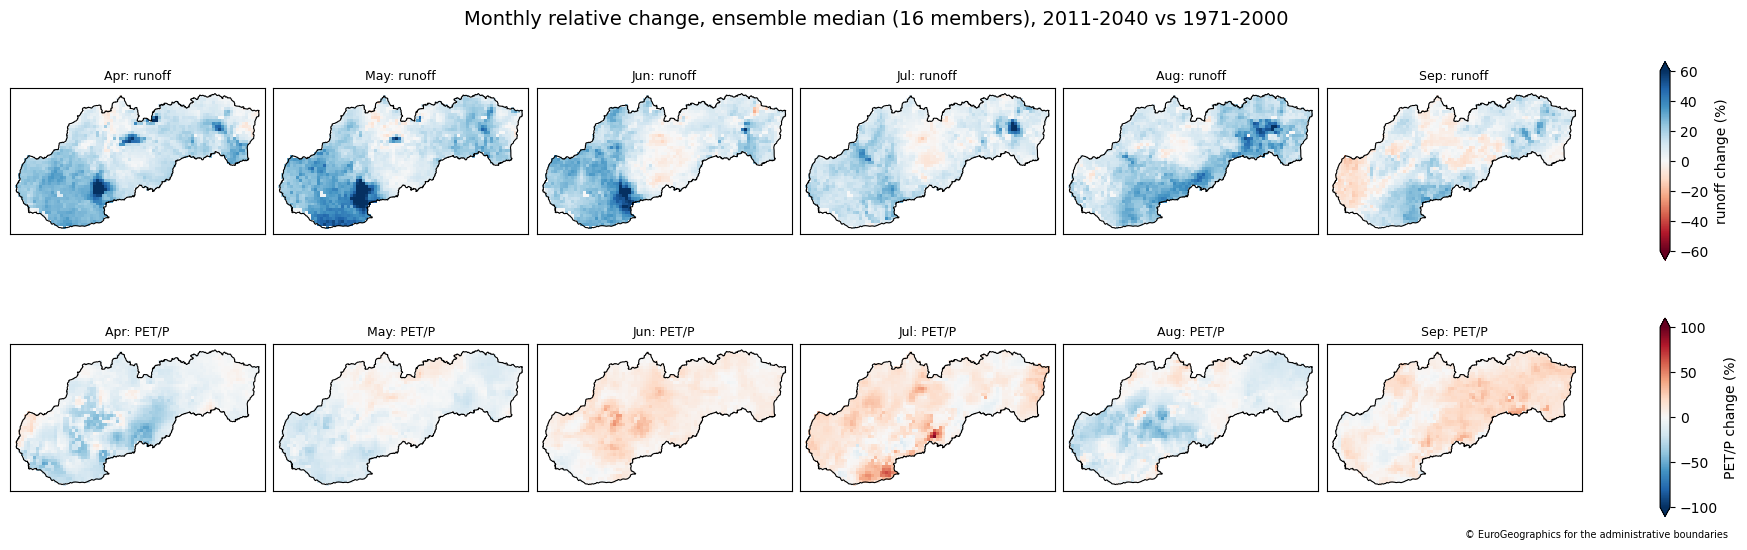

In [16]:
# Define the field of view for the maps as maximum of a box around Slovakia's boundary plus PAD (10,000 m)
minx, miny, maxx, maxy = sk_poly.bounds
PAD = 10_000

def draw(ax, field, title, **kw):
    """One 2-D field in EPSG:3035 metres, shown only inside Slovakia, with the border on top."""
    m = ax.pcolormesh(Xw, Yw, np.where(inside, field, np.nan), shading="nearest", rasterized=True, **kw)
    boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_xlim(minx - PAD, maxx + PAD)
    ax.set_ylim(miny - PAD, maxy + PAD)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title, fontsize=9)
    return m

season_months = months_ref[season_idx]

def season_months_da(path, var):
    """Windowed growing-season months for one member, relabelled with month numbers."""
    with xr.open_dataset(path) as ds:
        da = ds[var].isel(win).isel(time=season_idx).load().astype("float64")
    return da.drop_vars("lon", errors="ignore").assign_coords(time=season_months)       # Timestamps replaced with month numbers for concatenation 

run_months, arid_months = [], []
for row in tqdm(members.itertuples(), total=len(members), desc="monthly medians"):
    run_months.append(season_months_da(row.run_path, "run_ymonmean"))
    arid_months.append(season_months_da(row.arid_path, "aridpot_ymonmean"))

run_month_med  = xr.concat(run_months,  dim="member").median("member")
arid_month_med = xr.concat(arid_months, dim="member").median("member")
period_label = PERIOD.replace("_", "-")


n_m = len(season_idx)
fig, axes = plt.subplots(2, n_m, figsize=(2.9 * n_m, 5.4), constrained_layout=True)
norm_run, norm_arid = TwoSlopeNorm(vmin=-60, vcenter=0, vmax=60), TwoSlopeNorm(vmin=-100, vcenter=0, vmax=100)
for j, m in enumerate(season_months):
    label = calendar.month_abbr[int(m)]
    m_r = draw(axes[0, j], run_month_med.sel(time=m).values,  f"{label}: runoff", cmap="RdBu",   norm=norm_run)
    m_a = draw(axes[1, j], arid_month_med.sel(time=m).values, f"{label}: PET/P",  cmap="RdBu_r", norm=norm_arid)
fig.colorbar(m_r, ax=axes[0, :], shrink=0.8, extend="both", label="runoff change (%)")
fig.colorbar(m_a, ax=axes[1, :], shrink=0.8, extend="both", label="PET/P change (%)")
fig.suptitle(f"Monthly relative change, ensemble median ({len(members)} members), "
             f"{period_label} vs 1971-2000", fontsize=14)
fig.text(0.99, 0.01, "© EuroGeographics for the administrative boundaries", ha="right", va="bottom", fontsize=7) # Required map attribution
plt.show()

**#16. Visualizing the ensemble median of the entire growing season, 2011-2040** 

Dot stippling added per IPCC convention to show cells where models disagree.

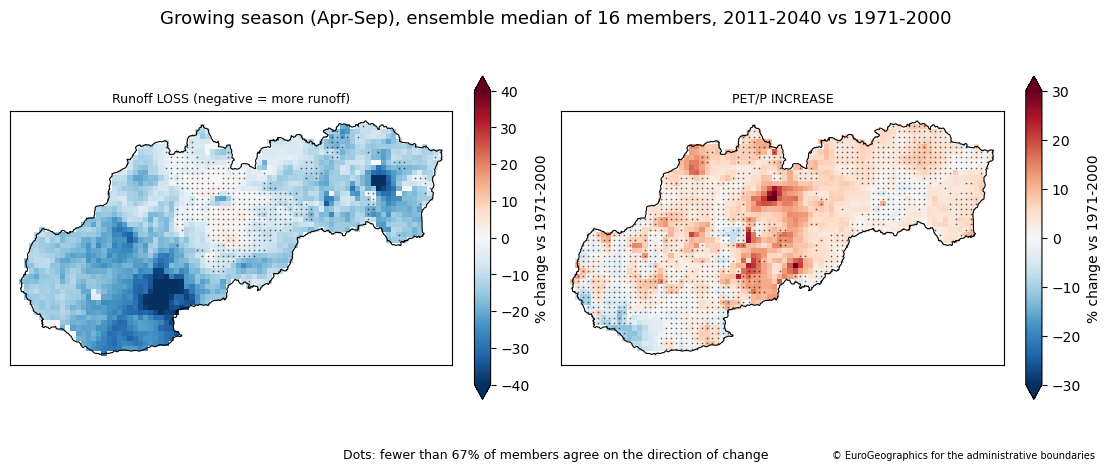

In [17]:
def stipple(ax, robust, size=1.5):
    """Dotting the cells inside Slovakia where fewer than 'ROBUST' of the members agree on the sign of change."""
    weak = inside & ~robust
    ax.scatter(Xw[weak], Yw[weak], s=size, c="black", linewidths=0, alpha=0.6)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
m1 = draw(axes[0], runoff_loss_pct.values, "Runoff LOSS (negative = more runoff)",
          cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-40, vcenter=0, vmax=40))
m2 = draw(axes[1], aridity_chg_mean.values, "PET/P INCREASE",
          cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-30, vcenter=0, vmax=30))
stipple(axes[0], robust_runoff)
stipple(axes[1], robust_arid)
fig.colorbar(m1, ax=axes[0], shrink=0.8, extend="both", label="% change vs 1971-2000")
fig.colorbar(m2, ax=axes[1], shrink=0.8, extend="both", label="% change vs 1971-2000")
fig.suptitle(f"Growing season (Apr-Sep), ensemble median of {len(members)} members, "
             f"{period_label} vs 1971-2000", fontsize=13)
fig.supxlabel(f"Dots: fewer than {ROBUST:.0%} of members agree on the direction of change", fontsize=9)
fig.text(0.99, 0.01, "© EuroGeographics for the administrative boundaries", ha="right", va="bottom", fontsize=7) # Required map attribution
plt.show()

**#17. Map of the 5 classes of the water stress indicator**

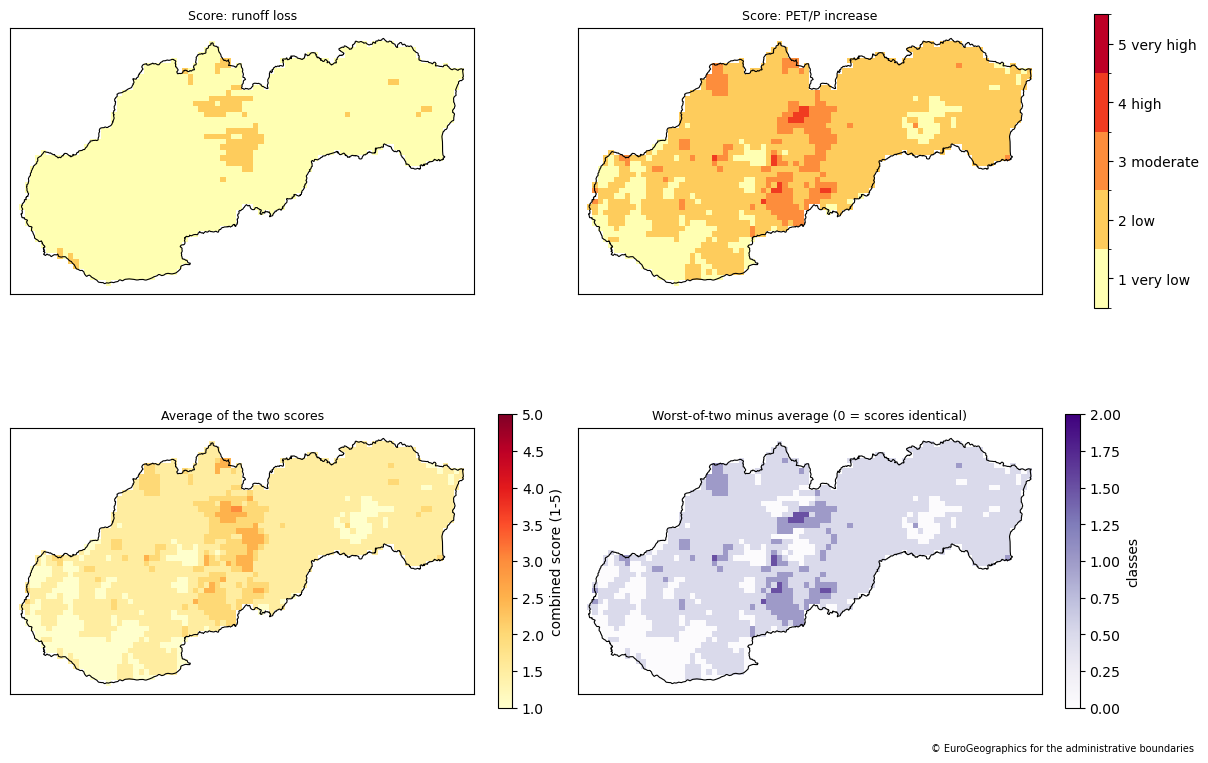

In [18]:
class_cmap = ListedColormap(["#ffffb2", "#fecc5c", "#fd8d3c", "#f03b20", "#bd0026"])
class_norm = BoundaryNorm(np.arange(0.5, 6.5, 1.0), class_cmap.N)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
mA = draw(axes[0, 0], score_runoff, "Score: runoff loss", cmap=class_cmap, norm=class_norm)
mB = draw(axes[0, 1], score_arid, "Score: PET/P increase", cmap=class_cmap, norm=class_norm)
mC = draw(axes[1, 0], score_mean, "Average of the two scores", cmap="YlOrRd", vmin=1, vmax=5)
mD = draw(axes[1, 1], score_worst - score_mean, "Worst-of-two minus average (0 = scores identical)", cmap="Purples", vmin=0, vmax=2)
cb = fig.colorbar(mA, ax=axes[0, :], ticks=[1, 2, 3, 4, 5], shrink=0.75)
cb.ax.set_yticklabels([f"{c} {CLASS_NAMES[c]}" for c in range(1, 6)])
fig.colorbar(mC, ax=axes[1, 0], shrink=0.75, label="combined score (1-5)")
fig.colorbar(mD, ax=axes[1, 1], shrink=0.75, label="classes")
fig.text(0.99, 0.01, "© EuroGeographics for the administrative boundaries", ha="right", va="bottom", fontsize=7) # Required map attribution
plt.show()

**#18. Save/Export results**

In [19]:
assert GRID_IS_REGULAR, "export uses 1-D EPSG:3035 coordinates; the grid check in #6 must pass"

RUN_TAG    = f"{EXPERIMENT}_{PERIOD}"                                           # e.g. rcp_4_5_2011_2040. Matches this notebook's name.
EXPORT_NC  = OUT_DIR / f"water_stress_{RUN_TAG}.nc"
EXPORT_CLS = OUT_DIR / f"water_stress_{RUN_TAG}_classes.csv"                    
EXPORT_SUM = OUT_DIR / f"water_stress_{RUN_TAG}_summary.csv" 

# Member label without the scenario, so the same model chain matches across RCP notebooks
model_chain = ["_".join([r.hydro_model, r.gcm, r.member, r.rcm]) for r in members.itertuples()]
assert len(model_chain) == len(keys), "member table and ensemble arrays are out of step"

def on_grid(a):
    """2-D (y, x) array -> float32 variable, NaN outside Slovakia."""
    return (("y", "x"), np.where(inside, np.asarray(a, dtype="float64"), np.nan).astype("float32"))

def on_members(a):
    """3-D (member, y, x) array -> float32 variable, NaN outside Slovakia."""
    return (("member", "y", "x"), np.where(inside, np.asarray(a, dtype="float64"), np.nan).astype("float32"))

ds_out = xr.Dataset(
    data_vars={
        "inside":                 (("y", "x"), inside.astype("int8")),
        # ensemble medians and model spread (positive = drier)
        "runoff_loss_median":     on_grid(runoff_loss_pct),
        "petp_change_median":     on_grid(aridity_chg_mean),
        "runoff_loss_iqr":        on_grid(iqr_runoff),
        "petp_change_iqr":        on_grid(iqr_arid),
        # share of members projecting drier conditions (0-1)
        "share_runoff_loss":      on_grid(agree_runoff),
        "share_petp_increase":    on_grid(agree_arid),
        # indicator classes
        "class_runoff":           on_grid(score_runoff),
        "class_petp":             on_grid(score_arid),
        "class_mean":             on_grid(score_mean),
        "class_worst":            on_grid(score_worst),
        # robustness flags (1 = robust, 0 = not)
        "robust_runoff":          on_grid(robust_runoff),
        "robust_petp":            on_grid(robust_arid),
        "robust_mean":            on_grid(robust_mean),
        "robust_worst":           on_grid(robust_worst),
        # class agreement: share of members in the ensemble-median class (0-1)
        "class_agreement_runoff": on_grid(agree_cls["runoff"]),
        "class_agreement_petp":   on_grid(agree_cls["PET/P"]),
        "class_agreement_mean":   on_grid(agree_cls["combined mean"]),
        "class_agreement_worst":  on_grid(agree_cls["worst-of-two"]),
        # per-member growing-season values, for recomputing statistics on shared members
        "runoff_loss_member":     on_members(runoff_loss_ens),
        "petp_change_member":     on_members(aridity_ens),
    },
    coords={
        "x":      ("x", x1d[win["x"]]),
        "y":      ("y", y1d[win["y"]]),
        "member": ("member", model_chain),
        "lat":    (("y", "x"), lat_w.astype("float32")),
        "lon":    (("y", "x"), lon_w.astype("float32")),
    },
    attrs={
        "title":             "Growing-season water stress indicator, Slovakia",
        "experiment":        EXPERIMENT,
        "period":            PERIOD,
        "reference_period":  "1971_2000",
        "growing_months":    GROWING_MONTHS,
        "n_members":         len(model_chain),
        "robust_threshold":  ROBUST,
        "cap_applied":       int(USE_CAP),
        "cap_pct":           CAP_PCT,
        "runoff_loss_edges": RUNOFF_LOSS_EDGES,
        "petp_edges":        ARIDITY_EDGES,
        "class_names":       json.dumps(CLASS_NAMES),
        "sign_convention":   "positive = drier (runoff loss, PET/P increase)",
        "crs":               ANALYSIS_CRS,
        "source":            "C3S sis-hydrology-variables-derived-projections, DOI 10.24381/cds.73237ad6",
        "licence": ("CC-BY 4.0; contains modified Copernicus Climate Change Service information 2026. "
               "Neither the European Commission nor ECMWF is responsible for any use that may be made of the "
               "Copernicus information or data it contains. "
               "Slovakia mask derived from Eurostat GISCO boundaries: © EuroGeographics for the administrative boundaries"),
        "created_utc":       pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),
    },
)
for v in ["runoff_loss_median", "petp_change_median", "runoff_loss_member", "petp_change_member"]:
    ds_out[v].attrs["units"] = "%"
for v in ["runoff_loss_iqr", "petp_change_iqr"]:
    ds_out[v].attrs["units"] = "percentage points"
ds_out["x"].attrs.update(units="m", long_name="easting (EPSG:3035)")
ds_out["y"].attrs.update(units="m", long_name="northing (EPSG:3035)")
ds_out.to_netcdf(EXPORT_NC)


# ---------------------CLASS TABLES (long format)---------------------
displays = [("runoff",        score_runoff, robust_runoff, agree_cls["runoff"],        CLASS_LEVELS),
            ("PET/P",         score_arid,   robust_arid,   agree_cls["PET/P"],         CLASS_LEVELS),
            ("worst-of-two",  score_worst,  robust_worst,  agree_cls["worst-of-two"],  CLASS_LEVELS),
            ("combined mean", score_mean,   robust_mean,   agree_cls["combined mean"], None)]
cls_tables = []
for name, s, rob, agr, levels in displays:
    t = class_table(s, rob, agr, levels=levels).rename_axis("class").reset_index()
    t.insert(0, "display", name)
    cls_tables.append(t)
classes = (pd.concat(cls_tables, ignore_index=True)
             .rename(columns={"% of cells": "pct_cells", "km2": "area_km2",
                              "% robust": "pct_robust", "class agreement %": "class_agreement_pct"}))
classes.insert(0, "period", PERIOD)
classes.insert(0, "experiment", EXPERIMENT)
classes.to_csv(EXPORT_CLS, index=False)


# ---------------------HEADLINE SUMMARY (one row)---------------------
v_run, v_arid = runoff_loss_pct.values[inside], aridity_chg_mean.values[inside]
short = {"runoff": "runoff", "PET/P": "petp", "combined mean": "mean", "worst-of-two": "worst"}
summary_row = {
    "experiment": EXPERIMENT,
    "period": PERIOD,
    "n_members": len(model_chain),
    "runoff_loss_median": np.median(v_run),
    "runoff_loss_p5": np.percentile(v_run, 5),
    "runoff_loss_p95": np.percentile(v_run, 95),
    "petp_change_median": np.median(v_arid),
    "petp_change_p5": np.percentile(v_arid, 5),
    "petp_change_p95": np.percentile(v_arid, 95),
    "pct_robust_runoff": 100 * robust_runoff[inside].mean(),
    "pct_robust_petp": 100 * robust_arid[inside].mean(),
    "iqr_runoff_median": np.median(iqr_runoff[inside]),
    "iqr_petp_median": np.median(iqr_arid[inside]),
    **{f"class_agreement_{short[k]}_median": 100 * np.median(v[valid]) for k, v in agree_cls.items()},
    "members": ";".join(model_chain),
}
pd.DataFrame([summary_row]).round(2).to_csv(EXPORT_SUM, index=False)


# ---------------------CHECK---------------------
with xr.open_dataset(EXPORT_NC) as chk:                                        # `with` closes the file, so reruns can overwrite it
    assert np.allclose(chk["runoff_loss_median"].values, ds_out["runoff_loss_median"].values, equal_nan=True)
    print(f"wrote {EXPORT_NC.name}: {dict(chk.sizes)}, {len(chk.data_vars)} variables")
print(f"wrote {EXPORT_CLS.name} ({len(classes)} rows) and {EXPORT_SUM.name}")
display(pd.DataFrame([summary_row]).drop(columns="members").round(2).T.rename(columns={0: RUN_TAG}))

wrote water_stress_rcp_4_5_2011_2040.nc: {'y': 53, 'x': 90, 'member': 16}, 21 variables
wrote water_stress_rcp_4_5_2011_2040_classes.csv (20 rows) and water_stress_rcp_4_5_2011_2040_summary.csv


,rcp_4_5_2011_2040
experiment,rcp_4_5
period,2011_2040
n_members,16
runoff_loss_median,-13.91
runoff_loss_p5,-31.4
runoff_loss_p95,-0.0
petp_change_median,4.18
petp_change_p5,-3.47
petp_change_p95,13.02
pct_robust_runoff,79.66


## Conclusion: Results in Plain Language

**Period and scenario:** 2011–2040 compared with 1971–2000, under a moderate-emissions scenario (RCP 4.5).

**Season:** the Slovak growing season, April–September.

**What was measured**
- **Runoff:** water that reaches streams and rivers. *Less runoff = drier.*
- **PET/P:** how much water the atmosphere could evaporate (potential evapotranspiration, PET) compared with how much falls as precipitation (P). *A higher ratio = drier.*

This demo combines **16 model runs**: 8 climate simulations, each passed through 2 different hydrological models. The maps show the median value of the 16 members. Where fewer than two-thirds of the models agree on whether a place gets wetter or drier, the map is dotted per IPCC convention.

**Key findings**
1. **Growing-season runoff is likely to increase slightly.** At a typical location, the middle estimate is about 14 % more runoff than in 1971–2000, and only 5 % of Slovakia shows a decrease, and then only a modest one <10%. Across about 80% of the country, at least two-thirds of the models agree on the direction. The amount of runoff increase is less certain: in a typical location, the models' estimates spread across about 28 percentage points.

2. **The change in evaporative demand relative to rainfall is small and uncertain.** The typical change is **about +4%**, ranging from −13% to +31% across the country. The models agree on the direction in only **about 39% of Slovakia**, and their spread (about 21 percentage points) is roughly five times larger than the typical change. For this period, the signal can't be distinguished from disagreement between models.

3. **Indicator classes.** On runoff alone, about **95% of Slovakia** falls in the "very low" water-stress class. On PET/P, about **73%** is "low", **10%** "moderate" and **under 1%** "high". The combined (worst-of-two) map closely follows PET/P, because runoff points towards wetter conditions almost everywhere. Even where the middle estimate assigns a class, typically **only about a third of the models** would assign the same class for PET/P, so treat the classes as indicative rather than precise.

4. **Why one model is not enough.** I built an initial version of this with a single model run to get the architecture right. This single model run turned out to be the driest of all 16. On its own, it suggested falling runoff and a sharp rise in May evaporative demand which looked quite striking on the map. The full set of models points the opposite way for runoff. This was an interesting demo result to illustrate the importance of using a model ensemble.

### Caveats
Data used here are simple ratios and lack full context (i.e. a 10% change may or may not be a big difference depending on the baseline)

All negative values here represent increases in runoff or decreasing PET/P ratio (wetter), which are collapsed into the single "very low" bin for the indicator. This could represent wetter conditions potentially coinciding with increased flood risk, which I may add as an acute hazard using the CLIMADA Python library in a separate notebook.

- In this dataset, there is **no near-term drying of the growing season** under a moderate-emissions scenario. The only drying signal comes from evaporative demand, and this signal is weak.
- **30-year averages hide individual drought years.** A wetter average is compatible with occasional severe dry summers, which matter most for agriculture.
- This notebook includes only the RCP4.5 emissions scenario and 2011-2040 time period. The models are weighted equally, although several share the same global climate model, and changes are averaged across months as percentages. Future work will address some of these issues: 

### Future Work Roadmap
- Compare a different emissions scenario (RCP 8.5 next)
- Create bi-directional indicator (e.g. -5 for most increase in runoff, +5 for most decrease in runoff)
- Add an agricultural exposure layer (land use data)
- Add catchment basin data 
- Explore 2041-2070 timeframe and possibly beyond
- Test if runoff increases are seasonal
- Add a flood hazard layer for areas with very high runoff increases and/or extreme seasonality.